# 05 · Política obtenida, modelo de valor esperado y VSS

En este notebook se analiza la política que encontró el L-shaped anidado. Se presenta cuánto invierte en cada activo en los 73 nodos de decisión, cómo cambian esas proporciones según lo que haya ocurrido en el primer trimestre y qué resultados produce en los 512 finales posibles: riqueza esperada, déficit esperado y probabilidad de alcanzar la meta. Después se compara con una estrategia más simple, el modelo de valor esperado, que ignora la incertidumbre y supone que cada activo rinde siempre su promedio. Esa estrategia se pone a prueba en las mismas 512 trayectorias, y la diferencia entre su costo esperado (EEV) y el de la política estocástica (RP) da el valor de la solución estocástica, $VSS = EEV - RP$. Al final, las proporciones de la estrategia simple se guardan de forma definitiva para aplicarlas también en 2026. Todo el análisis ocurre dentro del árbol, con los datos de calibración; los de 2026 no se usan.

In [1]:
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.optimize import linprog
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 170)
ASSET_COLORS = {"SPY": "#1f77b4", "LQD": "#2ca02c", "GLD": "#d4a017"}

## 1. Carga y verificación de entradas

Se verifican los hashes de los parámetros, del árbol y de la política congelada en el notebook 04.

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PARAMS_DIR = ROOT / "results" / "parameters"
TREE_DIR = ROOT / "results" / "tree"
POLICY_DIR = ROOT / "results" / "policy"
TABLES_DIR = ROOT / "results" / "tables"
FIGURES_DIR = ROOT / "results" / "figures"
for d in [TABLES_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

params_path = PARAMS_DIR / "calibration_parameters.json"
params_hash = (PARAMS_DIR / "calibration_parameters.sha256").read_text().strip()
assert sha256_of(params_path) == params_hash, "Los parámetros congelados cambiaron."
params = json.loads(params_path.read_text(encoding="utf-8"))

tree_meta = json.loads((TREE_DIR / "tree_metadata.json").read_text(encoding="utf-8"))
assert sha256_of(ROOT / tree_meta["csv_file"]) == tree_meta["csv_sha256"], "El árbol cambió."
tree = pd.read_csv(ROOT / tree_meta["csv_file"], keep_default_na=False, na_values=[""])

pol_meta_path = POLICY_DIR / "lshaped_policy.json"
assert sha256_of(pol_meta_path) == (POLICY_DIR / "lshaped_policy.sha256").read_text().strip(), \
    "La política congelada cambió desde el notebook 04."
pol_meta = json.loads(pol_meta_path.read_text(encoding="utf-8"))
assert sha256_of(ROOT / pol_meta["policy_csv"]) == pol_meta["policy_csv_sha256"]
assert pol_meta["calibration_parameters_sha256"] == params_hash
assert pol_meta["tree_csv_sha256"] == tree_meta["csv_sha256"]
policy = pd.read_csv(ROOT / pol_meta["policy_csv"], keep_default_na=False, na_values=[""])

TICKERS = params["tickers"]
N_ASSETS = len(TICKERS)
B_CAP, M_GOAL, LAM = params["b"], params["M"], params["lambda"]
ACTIVE_STATES = params["active_states"]
Q_HAT = {u: params["states"][u]["q_hat"] for u in ACTIVE_STATES}
R_HAT = {u: np.array([params["states"][u]["R_hat"][t] for t in TICKERS]) for u in ACTIVE_STATES}
R_BAR = np.array([params["R_bar_EV"][t] for t in TICKERS])
H = int(tree["t"].max())
RP = pol_meta["RP_expected_cost"]

# Tolerancia monetaria para decidir si una hoja alcanza la meta (miles de USD): 1e-6 = USD 0.001
GOAL_TOL = 1e-6

print(f"Política L-shaped verificada: RP = {RP:.10f} (brecha {pol_meta['rel_gap']:.1e}, "
      f"{pol_meta['iterations']} ciclos)")
print(f"Tolerancia monetaria para la meta: V ≥ M − {GOAL_TOL:g} miles de USD")

Política L-shaped verificada: RP = 1.2711985137 (brecha -6.5e-12, 17 ciclos)
Tolerancia monetaria para la meta: V ≥ M − 1e-06 miles de USD


## 2. Política estocástica: tabla de los 73 nodos

$V^{t,*}_k = \sum_i x^{t,*}_{i,k}$ y $f^t_{i,k} = x^{t,*}_{i,k}/V^{t,*}_k$. Los denominadores son positivos porque $b > 0$ y todos los factores son positivos. La tabla completa se exporta; aquí se muestran la raíz y los ocho nodos de etapa 2.

In [3]:
X_COLS = [f"x_{tk}" for tk in TICKERS]
F_COLS = [f"f_{tk}" for tk in TICKERS]
policy["V"] = policy[X_COLS].sum(axis=1)
for tk in TICKERS:
    policy[f"f_{tk}"] = policy[f"x_{tk}"] / policy["V"]

assert len(policy) == sum(len(g) for _, g in tree[~tree["is_leaf"]].groupby("t"))
assert (policy["V"] > 0).all(), "Hay riquezas no positivas."
assert ((policy[F_COLS] >= -1e-12) & (policy[F_COLS] <= 1 + 1e-12)).all().all()
assert np.allclose(policy[F_COLS].sum(axis=1), 1.0)
print(f"✔ {len(policy)} nodos de decisión; riquezas positivas; proporciones en [0, 1] que suman 1.")

def node_table(df):
    out = df[["t", "k", "history", "p_cum", "V"] + X_COLS + F_COLS].copy()
    out.columns = ["t", "k", "historia", "p^t_k", "V^t_k"] + [f"x {tk}" for tk in TICKERS] + [f"f {tk}" for tk in TICKERS]
    return out.set_index(["t", "k"])

with pd.option_context("display.float_format", "{:.4f}".format):
    display(node_table(policy[policy["t"] <= 2]))
node_table(policy).to_csv(TABLES_DIR / "05_policy_73_nodes.csv", float_format="%.12g")

✔ 73 nodos de decisión; riquezas positivas; proporciones en [0, 1] que suman 1.


historia  p^t_k    V^t_k   x SPY  x LQD   x GLD  f SPY  f LQD  f GLD
t k                                                                     
1 1     raíz 1.0000 100.0000 84.2273      0 15.7727 0.8423 0.0000 0.1577
2 1      AAA 0.4844 106.9771 74.6236      0 32.3535 0.6976 0.0000 0.3024
  2      AAB 0.0938 105.2606 77.8735      0 27.3872 0.7398 0.0000 0.2602
  3      ABA 0.0469 108.2497 85.1168      0 23.1328 0.7863 0.0000 0.2137
  4      ABB 0.1719 102.5443 71.4172      0 31.1271 0.6965 0.0000 0.3035
  5      BAA 0.0469  93.7815 93.7815      0  0.0000 1.0000 0.0000 0.0000
  6      BAB 0.0469  96.5062 81.7771      0 14.7292 0.8474 0.0000 0.1526
  7      BBA 0.0625  92.6050 92.6050      0  0.0000 1.0000 0.0000 0.0000
  8      BBB 0.0469  92.2010 92.2010      0  0.0000 1.0000 0.0000 0.0000

## 3. Proporciones de la raíz y de los nodos de etapa 2 

Cada barra es un nodo: la raíz (decisión de diciembre de 2025) y los ocho nodos de marzo de 2026, uno por cada terna $z_1$ posible. Así se ve cómo cambia la composición del portafolio según lo que se observe en el primer trimestre.

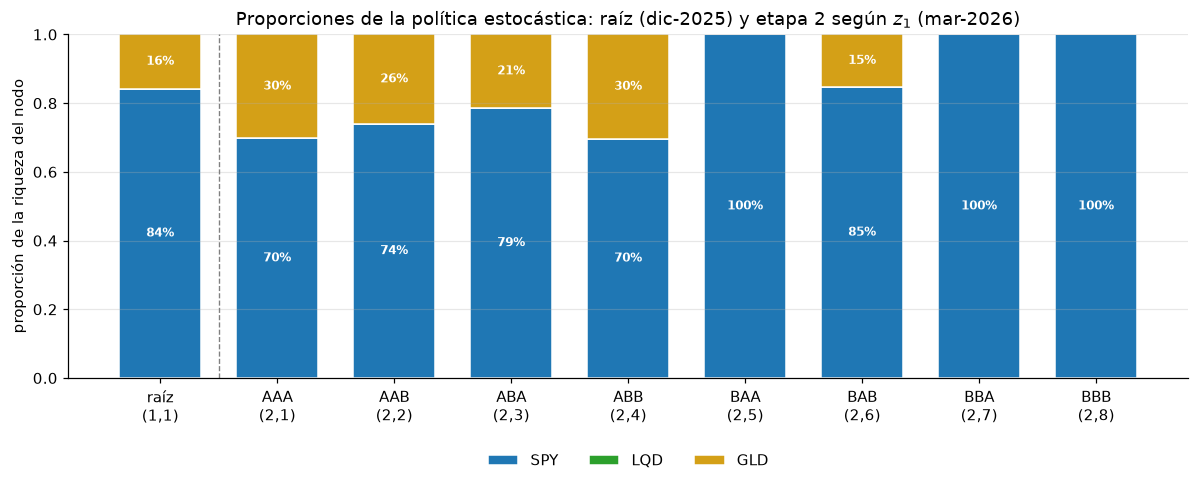

In [4]:
sub = policy[policy["t"] <= 2].reset_index(drop=True)
labels = ["raíz\n(1,1)"] + [f"{h}\n(2,{k})" for h, k in zip(sub["history"][1:], sub["k"][1:])]
fig, ax = plt.subplots(figsize=(11, 4.6))
bottom = np.zeros(len(sub))
for tk in TICKERS:
    vals = sub[f"f_{tk}"].to_numpy()
    ax.bar(labels, vals, bottom=bottom, color=ASSET_COLORS[tk], label=tk, width=0.7, edgecolor="white")
    for i, (v, b0) in enumerate(zip(vals, bottom)):
        if v >= 0.06:
            ax.text(i, b0 + v / 2, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white", weight="bold")
    bottom += vals
ax.axvline(0.5, color="gray", lw=0.9, ls="--")
ax.set_ylim(0, 1); ax.set_ylabel("proporción de la riqueza del nodo")
ax.set_title("Proporciones de la política estocástica: raíz (dic-2025) y etapa 2 según $z_1$ (mar-2026)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "05_stage2_proportions.png", bbox_inches="tight"); plt.show()

## 4. Hojas de la política estocástica

Se recalcula la riqueza de cada hoja de forma independiente, propagando las **proporciones** $f$ desde la raíz con los factores de cada rama: $V^{t+1} = V^t \sum_i f^t_{i,k}\,\hat R_i(u)$. Debe coincidir con la riqueza de las hojas guardada por el notebook 04 y con RP. Esa misma función de propagación se usa después para la regla EV, de modo que las dos políticas se evalúan exactamente igual.

In [5]:
leaves_tree = tree[tree["is_leaf"]].reset_index(drop=True)

def evaluate_rule(proportions_for):
    # proportions_for(t, k) -> vector de proporciones del nodo (t,k). Devuelve las 512 hojas.
    rows = []
    for leaf in leaves_tree.itertuples():
        hist = leaf.history.split("|")
        V, k = B_CAP, 1
        for t in range(1, H):
            f = proportions_for(t, k)
            V = V * float(f @ R_HAT[hist[t - 1]])
            k = (k - 1) * len(ACTIVE_STATES) + ACTIVE_STATES.index(hist[t - 1]) + 1
        assert k == leaf.k
        y, w = max(V - M_GOAL, 0.0), max(M_GOAL - V, 0.0)
        rows.append({"k": leaf.k, "history": leaf.history, "p_cum": leaf.p_cum, "V4": V,
                     "excess": y, "deficit": w, "cost": LAM * w - y,
                     "meets_goal": int(V >= M_GOAL - GOAL_TOL)})
    return pd.DataFrame(rows)

F_BY_NODE = {(r.t, r.k): np.array([getattr(r, c) for c in F_COLS]) for r in policy.itertuples()}
leaves_sp = evaluate_rule(lambda t, k: F_BY_NODE[(t, k)])

saved = pd.read_csv(ROOT / pol_meta["leaves_csv"], keep_default_na=False, na_values=[""])
assert np.allclose(leaves_sp["V4"], saved["V4"], rtol=0, atol=1e-7), "Las hojas no coinciden con el notebook 04."
RP_check = float((leaves_sp["p_cum"] * leaves_sp["cost"]).sum())
assert abs(RP_check - RP) <= 1e-8 * max(1, abs(RP))
assert abs(leaves_sp["p_cum"].sum() - 1) < 1e-12
print(f"✔ Propagación por proporciones reproduce las 512 hojas del notebook 04; RP = {RP_check:.10f}")
leaves_sp.to_csv(TABLES_DIR / "05_leaves_512_stochastic.csv", index=False, float_format="%.12g")

✔ Propagación por proporciones reproduce las 512 hojas del notebook 04; RP = 1.2711985137


## 5. Modelo de valor esperado (EV)

El modelo EV reemplaza el factor de cada activo en **cada** período por su promedio
$$\bar R_i = \sum_{u \in U} \hat q_u\, \hat R_i(u),$$
de modo que hay un único camino. Es distinto del equivalente determinista, que conserva todo el árbol. Su LP es

$$\min\; \lambda w - y \quad \text{s.a.}\quad \sum_i x^1_i = b,\quad \sum_i x^{t+1}_i = \bar R^T x^t \;(t = 1, 2),\quad \bar R^T x^3 - y + w = M,\quad x, y, w \ge 0.$$

Sus proporciones son $g^t_i = x^{EV}_{t,i} / \sum_j x^{EV}_{t,j}$. Como el camino es único y el objetivo es lineal por tramos y decreciente en la riqueza final, el modelo EV tiende a concentrar todo en el activo de mayor $\bar R_i$: no tiene ningún motivo para diversificar.

In [6]:
# Variables: x1 (3), x2 (3), x3 (3), y, w
n = 3 * N_ASSETS + 2
c = np.zeros(n); c[-2], c[-1] = -1.0, LAM
A = np.zeros((4, n)); bq = np.zeros(4)
A[0, 0:3] = 1.0; bq[0] = B_CAP
A[1, 3:6] = 1.0; A[1, 0:3] = -R_BAR
A[2, 6:9] = 1.0; A[2, 3:6] = -R_BAR
A[3, 6:9] = R_BAR; A[3, 9] = -1.0; A[3, 10] = 1.0; bq[3] = M_GOAL
res_ev = linprog(c, A_eq=A, b_eq=bq, bounds=(0, None), method="highs")
assert res_ev.status == 0, res_ev.message

x_ev = {t: res_ev.x[3 * (t - 1): 3 * t] for t in (1, 2, 3)}
V_ev = {t: x_ev[t].sum() for t in (1, 2, 3)}
G = {t: x_ev[t] / V_ev[t] for t in (1, 2, 3)}
V4_ev = float(R_BAR @ x_ev[3])

ev_tab = pd.DataFrame({f"t = {t}": np.r_[V_ev[t], x_ev[t], G[t]] for t in (1, 2, 3)},
                      index=["V^EV_t"] + [f"x {tk}" for tk in TICKERS] + [f"g {tk}" for tk in TICKERS])
print("R̄ =", {tk: round(float(v), 6) for tk, v in zip(TICKERS, R_BAR)})
with pd.option_context("display.float_format", "{:.6f}".format):
    display(ev_tab)
print(f"Riqueza final del camino promedio: {V4_ev:.6f}; valor óptimo del modelo EV: {res_ev.fun:.6f}")
print("(Este valor es el del camino promedio; no es el EEV, que se calcula sobre el árbol.)")

best = np.flatnonzero(np.isclose(R_BAR, R_BAR.max(), rtol=0, atol=1e-12))
if len(best) > 1:
    print("Atención: hay empate en el mayor R̄ entre", [TICKERS[i] for i in best],
          "; el modelo EV tiene óptimos múltiples y el solver eligió uno.")
for t in (1, 2, 3):
    assert np.isclose(G[t].sum(), 1.0) and (G[t] >= -1e-12).all()

R̄ = {'SPY': 1.036118, 'LQD': 1.010692, 'GLD': 1.02356}


,t = 1,t = 2,t = 3
V^EV_t,100.000000,103.611786,107.354022
x SPY,100.000000,103.611786,107.354022
x LQD,0.000000,0.000000,0.000000
x GLD,0.000000,0.000000,0.000000
g SPY,1.000000,1.000000,1.000000
g LQD,0.000000,0.000000,0.000000
g GLD,0.000000,0.000000,0.000000


Riqueza final del camino promedio: 111.231419; valor óptimo del modelo EV: -5.231419
(Este valor es el del camino promedio; no es el EEV, que se calcula sobre el árbol.)


## 6. EEV y VSS

Para saber qué tan buena es la estrategia simple en un mundo con incertidumbre, se aplica en las 512 trayectorias del árbol. En cada etapa se invierten sus proporciones fijas $g^t_i$ sobre la riqueza que haya en esa trayectoria, sin cambiarlas nunca según lo que haya ocurrido. Es una regla que no se adapta: los porcentajes son siempre los mismos, aunque los montos sí varían con la riqueza disponible. El costo esperado que resulta es el EEV, y la ventaja de la política estocástica se mide como

$$VSS = EEV - RP \ge 0.$$

El VSS no puede ser negativo, porque dentro del árbol ninguna regla puede tener un costo esperado menor que el de la política óptima. Se mide en las mismas unidades que el costo, es decir, penalización por déficit menos recompensa por exceso, así que no debe leerse como dinero ganado: es una diferencia de costo esperado, no un aumento directo de riqueza.

In [7]:
leaves_ev = evaluate_rule(lambda t, k: G[t])
EEV = float((leaves_ev["p_cum"] * leaves_ev["cost"]).sum())
VSS = EEV - RP
print(f"RP  = {RP:.10f}   (política estocástica)")
print(f"EEV = {EEV:.10f}   (regla EV evaluada en el árbol)")
print(f"VSS = EEV − RP = {VSS:.10f}")
assert VSS >= -1e-8 * max(1, abs(RP)), "VSS negativo más allá del error numérico: revisar."
print("✔ VSS ≥ 0 (salvo error numérico)")
leaves_ev.to_csv(TABLES_DIR / "05_leaves_512_ev.csv", index=False, float_format="%.12g")

RP  = 1.2711985137   (política estocástica)
EEV = 2.7532277765   (regla EV evaluada en el árbol)
VSS = EEV − RP = 1.4820292628
✔ VSS ≥ 0 (salvo error numérico)


## 7. Comparación de las dos políticas dentro del árbol

La tabla agregada resume las 512 hojas de cada política. Las cantidades son esperanzas o cuantiles **ponderados por** $p^4_k$. La probabilidad de alcanzar la meta es $\sum_k p^4_k\,\mathbf{1}\{V^4_k \ge M - \text{tol}\}$, con la tolerancia declarada arriba.

In [8]:
def wquantile(values, weights, q):
    o = np.argsort(values); v, w = values[o], weights[o]
    cw = np.cumsum(w) / w.sum()
    return float(v[np.searchsorted(cw, q, side="left")])

def summarize(lv):
    p, V = lv["p_cum"].to_numpy(), lv["V4"].to_numpy()
    EV_ = float(p @ V)
    return {
        "costo esperado": float(p @ lv["cost"]),
        "riqueza esperada": EV_,
        "desv. estándar de la riqueza": float(np.sqrt(p @ (V - EV_) ** 2)),
        "riqueza mínima": V.min(),
        "cuantil 5 % de la riqueza": wquantile(V, p, 0.05),
        "mediana de la riqueza": wquantile(V, p, 0.50),
        "riqueza máxima": V.max(),
        "exceso esperado": float(p @ lv["excess"]),
        "déficit esperado": float(p @ lv["deficit"]),
        "probabilidad de alcanzar la meta": float(p @ lv["meets_goal"]),
        "hojas que alcanzan la meta": int(lv["meets_goal"].sum()),
        "hojas con V a menos de 0.001 de M": int((np.abs(V - M_GOAL) < 1e-3).sum()),
    }

comparison = pd.DataFrame({"estocástica (RP)": summarize(leaves_sp), "regla EV (EEV)": summarize(leaves_ev)})
comparison["diferencia (EV − estocástica)"] = comparison["regla EV (EEV)"] - comparison["estocástica (RP)"]
with pd.option_context("display.float_format", "{:.6f}".format):
    display(comparison)
comparison.to_csv(TABLES_DIR / "05_policy_comparison.csv", float_format="%.12g")
print(f"VSS = {VSS:.6f} (diferencia de costo esperado, no de riqueza).")
print("Nota: la riqueza esperada de la regla EV puede ser mayor; el modelo penaliza el déficit con λ = "
      f"{LAM:g}, así que una riqueza media mayor no implica menor costo esperado.")

,estocástica (RP),regla EV (EEV),diferencia (EV − estocástica)
costo esperado,1.271199,2.753228,1.482029
riqueza esperada,110.417578,111.231419,0.813841
desv. estándar de la riqueza,9.408320,11.177010,1.768690
riqueza mínima,74.991707,73.352809,-1.638898
cuantil 5 % de la riqueza,90.791470,88.737235,-2.054235
mediana de la riqueza,110.169497,116.336750,6.167253
riqueza máxima,127.013706,127.764305,0.750599
exceso esperado,6.313837,7.892968,1.579131
déficit esperado,1.896259,2.661549,0.765290
probabilidad de alcanzar la meta,0.741215,0.599819,-0.141396


VSS = 1.482029 (diferencia de costo esperado, no de riqueza).
Nota: la riqueza esperada de la regla EV puede ser mayor; el modelo penaliza el déficit con λ = 4, así que una riqueza media mayor no implica menor costo esperado.


### Sensibilidad de la probabilidad de alcanzar la meta a la tolerancia

El costo terminal tiene un quiebre en $V = M$: por debajo cada dólar cuesta $\lambda$ y por encima solo resta 1. Por eso la política óptima suele llevar muchas hojas exactamente a la meta, y su riqueza queda en $M$ salvo el error numérico del solver (del orden de $10^{-9}$). La probabilidad de alcanzar la meta se vuelve entonces sensible a la tolerancia: con tolerancia cero, una hoja en $M - 10^{-12}$ contaría como incumplida. La tabla muestra esa sensibilidad para justificar la tolerancia declarada de $10^{-6}$ miles de USD (USD 0.001).

In [10]:
sens = []
for tol in [0.0, 1e-9, 1e-6, 1e-3, 1e-1]:
    row = {"tolerancia (miles USD)": f"{tol:g}"}
    for lv, name in [(leaves_sp, "estocástica"), (leaves_ev, "regla EV")]:
        row[f"P(meta) {name}"] = float(lv.loc[lv["V4"] >= M_GOAL - tol, "p_cum"].sum())
    sens.append(row)
sens = pd.DataFrame(sens).set_index("tolerancia (miles USD)")
with pd.option_context("display.float_format", "{:.6f}".format):
    display(sens)
near = leaves_sp.loc[np.abs(leaves_sp["V4"] - M_GOAL) < 1e-3, "V4"]
if len(near):
    print(f"{len(near)} hojas estocásticas a menos de 0.001 de M; desviación máxima |V − M| entre ellas: "
          f"{np.abs(near - M_GOAL).max():.2e} miles de USD.")
sens.to_csv(TABLES_DIR / "05_goal_probability_tolerance.csv", float_format="%.12g")

,P(meta) estocástica,P(meta) regla EV
tolerancia (miles USD),,
0,0.689941,0.599819
1e-09,0.741215,0.599819
1e-06,0.741215,0.599819
0.001,0.741215,0.599819
0.1,0.741215,0.599819


31 hojas estocásticas a menos de 0.001 de M; desviación máxima |V − M| entre ellas: 1.63e-10 miles de USD.


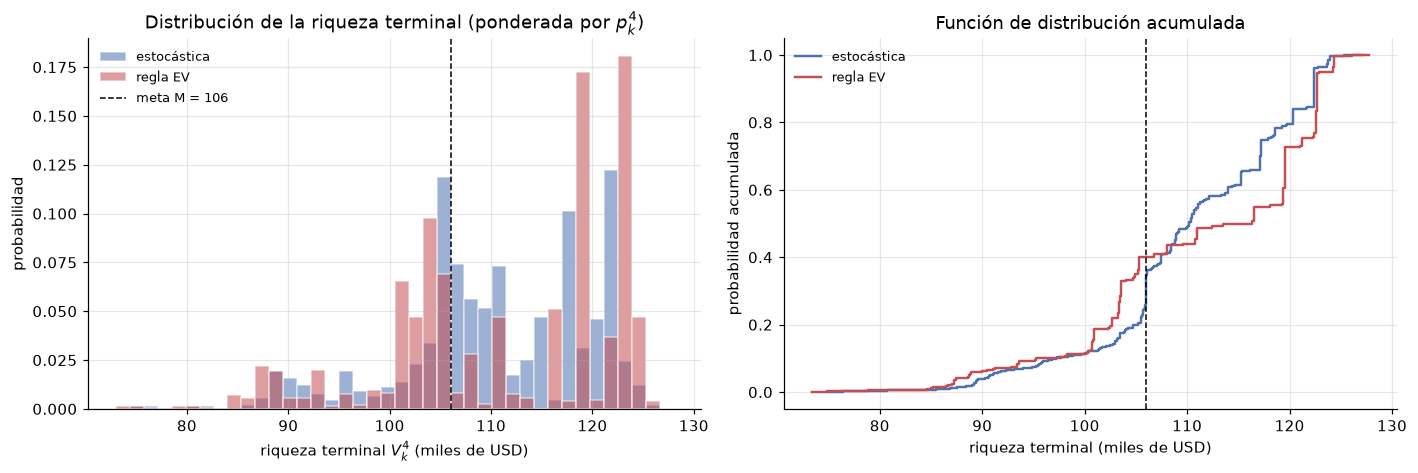

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
lo = min(leaves_sp["V4"].min(), leaves_ev["V4"].min()); hi = max(leaves_sp["V4"].max(), leaves_ev["V4"].max())
bins = np.linspace(np.floor(lo), np.ceil(hi), 41)
ax = axes[0]
for lv, name, col in [(leaves_sp, "estocástica", "#4c72b0"), (leaves_ev, "regla EV", "#c44e52")]:
    ax.hist(lv["V4"], bins=bins, weights=lv["p_cum"], alpha=0.55, color=col, label=name, edgecolor="white")
ax.axvline(M_GOAL, color="black", ls="--", lw=1, label=f"meta M = {M_GOAL:g}")
ax.set_xlabel("riqueza terminal $V^4_k$ (miles de USD)"); ax.set_ylabel("probabilidad")
ax.set_title("Distribución de la riqueza terminal (ponderada por $p^4_k$)")
ax.legend(frameon=False, fontsize=8.5)

ax = axes[1]
for lv, name, col in [(leaves_sp, "estocástica", "#4c72b0"), (leaves_ev, "regla EV", "#c44e52")]:
    o = lv.sort_values("V4")
    ax.step(o["V4"], o["p_cum"].cumsum(), where="post", color=col, label=name, lw=1.6)
ax.axvline(M_GOAL, color="black", ls="--", lw=1)
ax.set_xlabel("riqueza terminal (miles de USD)"); ax.set_ylabel("probabilidad acumulada")
ax.set_title("Función de distribución acumulada")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "05_terminal_wealth_distribution.png"); plt.show()

## 8. Insumos para las conclusiones

Para interpretar la política no basta con su costo; hay que entender por qué decide lo que decide. Las tablas siguientes responden tres preguntas: cómo cambia la composición del portafolio a medida que se observan los trimestres, si algún activo queda sin inversión en uno o varios nodos, y si algún activo rinde más que otro en todas las combinaciones posibles. Esto último ayudaría a explicar que el modelo prefiera sistemáticamente uno de ellos.

In [12]:
rows = []
for t, g in policy.groupby("t"):
    w = g["p_cum"] / g["p_cum"].sum()
    row = {"etapa t": t, "nodos": len(g)}
    for tk in TICKERS:
        row[f"f {tk} media ponderada"] = float(w @ g[f"f_{tk}"])
    for tk in TICKERS:
        row[f"nodos con {tk} = 0"] = int((g[f"x_{tk}"] <= 1e-9).sum())
    rows.append(row)
by_stage = pd.DataFrame(rows).set_index("etapa t")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(by_stage)

never = [tk for tk in TICKERS if (policy[f"x_{tk}"] <= 1e-9).all()]
print("Activos sin inversión en ningún nodo:", never if never else "ninguno")

dom = []
for a in TICKERS:
    for b_ in TICKERS:
        if a != b_:
            ge = [R_HAT[u][TICKERS.index(a)] >= R_HAT[u][TICKERS.index(b_)] for u in ACTIVE_STATES]
            dom.append({"comparación": f"R̂({a}) ≥ R̂({b_})", "estados": f"{sum(ge)} de {len(ge)}", "en todos": all(ge)})
display(pd.DataFrame(dom).set_index("comparación"))
by_stage.to_csv(TABLES_DIR / "05_composition_by_stage.csv", float_format="%.12g")

,nodos,f SPY media ponderada,f LQD media ponderada,f GLD media ponderada,nodos con SPY = 0,nodos con LQD = 0,nodos con GLD = 0
etapa t,,,,,,,
1,1,0.8423,0.0000,0.1577,0,1,0
2,8,0.7598,0.0000,0.2402,0,8,3
3,64,0.8035,0.0000,0.1965,0,64,40


Activos sin inversión en ningún nodo: ['LQD']


,estados,en todos
comparación,,
R̂(SPY) ≥ R̂(LQD),4 de 8,False
R̂(SPY) ≥ R̂(GLD),5 de 8,False
R̂(LQD) ≥ R̂(SPY),4 de 8,False
R̂(LQD) ≥ R̂(GLD),3 de 8,False
R̂(GLD) ≥ R̂(SPY),3 de 8,False
R̂(GLD) ≥ R̂(LQD),5 de 8,False


## 9. Registro definitivo de la regla EV

En el notebook 06, la estrategia simple también se aplica a lo que ocurrió en 2026, para compararla con la política estocástica. Por eso sus proporciones $g^t_i$ se guardan ahora, con su huella digital, antes de que cualquier notebook abra los datos de 2026. Así queda garantizado que las dos estrategias se fijaron con la misma información, la disponible a finales de 2025, y que ninguna se ajustó después de ver los resultados reales.

In [13]:
ev_policy = {
    "description": "Regla EV: proporciones fijas g^t_i del modelo de valor esperado (sección 5.1)",
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "calibration_parameters_sha256": params_hash,
    "R_bar": dict(zip(TICKERS, map(float, R_BAR))),
    "g": {str(t): dict(zip(TICKERS, map(float, G[t]))) for t in (1, 2, 3)},
    "ev_model_objective": float(res_ev.fun), "ev_path_terminal_wealth": V4_ev,
    "EEV": EEV, "RP": RP, "VSS": VSS,
    "application_rule": ("En cada etapa t se invierten las proporciones g^t_i de la riqueza realmente disponible, "
                         "sin cambiarlas según lo observado. La riqueza de esta política se actualiza por separado."),
}
ev_path = POLICY_DIR / "ev_policy.json"
ev_path.write_text(json.dumps(ev_policy, indent=2, ensure_ascii=False), encoding="utf-8")
(POLICY_DIR / "ev_policy.sha256").write_text(sha256_of(ev_path) + "\n")

print("Guardado:")
for p in [ev_path, POLICY_DIR / "ev_policy.sha256", TABLES_DIR / "05_policy_73_nodes.csv",
          TABLES_DIR / "05_leaves_512_stochastic.csv", TABLES_DIR / "05_leaves_512_ev.csv",
          TABLES_DIR / "05_policy_comparison.csv", TABLES_DIR / "05_composition_by_stage.csv",
          TABLES_DIR / "05_goal_probability_tolerance.csv",
          FIGURES_DIR / "05_stage2_proportions.png", FIGURES_DIR / "05_terminal_wealth_distribution.png"]:
    print("  ", p.relative_to(ROOT))

Guardado:
   results/policy/ev_policy.json
   results/policy/ev_policy.sha256
   results/tables/05_policy_73_nodes.csv
   results/tables/05_leaves_512_stochastic.csv
   results/tables/05_leaves_512_ev.csv
   results/tables/05_policy_comparison.csv
   results/tables/05_composition_by_stage.csv
   results/tables/05_goal_probability_tolerance.csv
   results/figures/05_stage2_proportions.png
   results/figures/05_terminal_wealth_distribution.png
